# Systemy AI – Laboratorium 5 - Mark Ponomarev - 437962
## Zadanie: który klasyfikator najlepiej rozpoznaje cukrzycę?

Zbiór **Pima Indians Diabetes**: 768 kobiet z plemienia Pima (Arizona, USA). Zadanie: na podstawie wyników badań przewidzieć, czy u pacjentki zdiagnozowano cukrzycę w ciągu 5 lat (`outcome` = 1).

Wykonaj całą procedurę z notatnika `SystemyAI_Lab5_Titanic_CV.ipynb`: porównaj klasyfikatory walidacją krzyżową, dostrój hiperparametry, wybierz najlepszy model i **dopiero na końcu, raz**, oceń go na zbiorze testowym. Cały kod piszesz sam(a).

| Kolumna | Znaczenie |
|---|---|
| `pregnancies` | liczba ciąż |
| `glucose` | stężenie glukozy po 2 h w doustnym teście obciążenia glukozą [mg/dl] |
| `blood_pressure` | ciśnienie rozkurczowe [mm Hg] |
| `skin_thickness` | grubość fałdu skórnego na tricepsie [mm] |
| `insulin` | stężenie insuliny po 2 h [μU/ml] |
| `bmi` | wskaźnik masy ciała [kg/m²] |
| `pedigree` | wskaźnik obciążenia rodzinnego cukrzycą |
| `age` | wiek [lata] |
| `outcome` | **etykieta**: 1 = cukrzyca, 0 = brak |

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Wczytanie danych
Plik nie ma wiersza nagłówka, więc nazwy kolumn trzeba podać samemu:

```python
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
kolumny = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
           "insulin", "bmi", "pedigree", "age", "outcome"]
df = pd.read_csv(URL, names=kolumny)
```
Zaimportuj potrzebne biblioteki, wczytaj dane do `df` i obejrzyj je (`shape`, `head()`, `describe()`).

In [1]:
# Twoje rozwiązanie
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
kolumny = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
           "insulin", "bmi", "pedigree", "age", "outcome"]
df = pd.read_csv(URL, names=kolumny)
print(df.shape)
print("\n", df.head())
df.describe()

(768, 9)

    pregnancies  glucose  blood_pressure  skin_thickness  insulin   bmi  \
0            6      148              72              35        0  33.6   
1            1       85              66              29        0  26.6   
2            8      183              64               0        0  23.3   
3            1       89              66              23       94  28.1   
4            0      137              40              35      168  43.1   

   pedigree  age  outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,pedigree,age,outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [2]:
# TEST
assert df.shape == (768, 9) and list(df.columns)[-1] == "outcome"
print("1 OK")

1 OK


---
## 2. EDA i ukryte braki
1. `class_share` – udział każdej klasy w `outcome`.
2. `df.isna().sum()` – czy są braki? Teraz policz `zeros` – liczbę **zer** w każdej kolumnie cech.
3. Narysuj `fig, axes = plt.subplots(1, 2, figsize=(12, 5))`: po lewej histogram `glucose`, po prawej histogram `insulin`, oba z kolorem według `outcome` (`sns.histplot(..., hue="outcome")`).

pregnancies       0
glucose           0
blood_pressure    0
skin_thickness    0
insulin           0
bmi               0
pedigree          0
age               0
outcome           0
dtype: int64

 outcome
0    500
1    268
Name: count, dtype: int64

 outcome
0    0.651042
1    0.348958
Name: proportion, dtype: float64


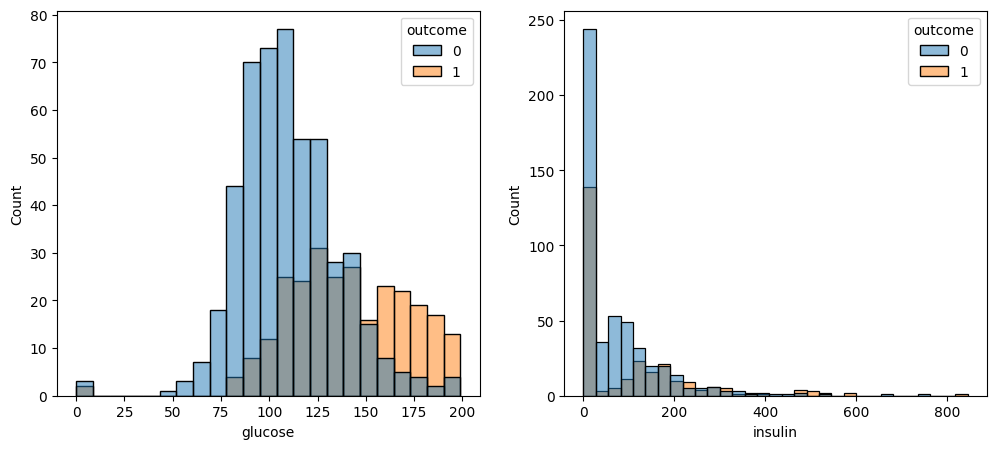

In [3]:
# Twoje rozwiązanie
class_share = df["outcome"].value_counts(normalize=True)
print(df.isna().sum()) # sprawdzamy braki
zeros = (df.drop(columns=["outcome"]) == 0).sum()

# Sprawdzenie do pytania 1
print("\n", df["outcome"].value_counts())
print("\n", df["outcome"].value_counts(normalize=True))

# Wykres
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="glucose", hue="outcome", ax=axes[0])
sns.histplot(data=df, x="insulin", hue="outcome", ax=axes[1])
plt.show()

In [4]:
# TEST
assert abs(class_share[0] - 0.651) < 1e-3
assert zeros["insulin"] == 374 and zeros["glucose"] == 5 and zeros["pregnancies"] == 111
print("2 OK")

2 OK


*Twoja odpowiedź:*
1. Jaką accuracy osiągnie baseline?
2. W których kolumnach zero jest **fizycznie niemożliwe** (żyjący człowiek nie może mieć takiej wartości), a w której jest zupełnie normalne?
3. Która cecha najwyraźniej różni chore i zdrowe pacjentki?
---
1. Model baseline osiągnie dokładnie takie accuracy, jaki jest udział najczęstszej klasy - czyli około 65,1% (klasa `outcome = 0`)


2. Fizycznie niemożliwe mieć zerowe ciśnienie krwi (`blood_pressure`), zerowej grubości skóry (`skin_thickness`), zerowego stężenia glukozy we krwi (`glucose`), ani zerowej masy ciała (`bmi`).
W przypadku kolumny `insulin`, choć w teorii przy cukrzycy typu 1 poziom insuliny może być bliski zera, w tym badaniu (2 godziny po obciążeniu glukozą) poziom 0 u żyjącego pacjenta jest nierealny. Natomiast, wartość zerowa w kolumnie `pregnancies` jest normalna, ponieważ oznacza po prostu, że pacjentka nigdy nie była w ciąży.

3. Najsilniejszą pojedynczą cechą różnicującą pacjentki zdrowe od chorych jest `glucose` (stężenie glukozy), co widać na wykresie.

---
## 3. Zamiana ukrytych braków na `NaN`
W kolumnach `glucose`, `blood_pressure`, `skin_thickness`, `insulin`, `bmi` zamień zera na `np.nan` (`replace(0, np.nan)`). Wynik zapisz w `df_clean` (kopia `df`), a liczbę braków w każdej kolumnie w `missing`.

Model nie wie, że zero oznacza brak. Dla niego „insulina = 0” to po prostu bardzo niska insulina – a takich „pomiarów” jest prawie połowa.

In [5]:
# Twoje rozwiązanie
df_clean = df.copy()
columns_to_clean = ["glucose", "blood_pressure", "skin_thickness", "insulin", "bmi"]
df_clean[columns_to_clean] = df_clean[columns_to_clean].replace(0, np.nan)
missing = df_clean.isna().sum()
print(missing)

pregnancies         0
glucose             5
blood_pressure     35
skin_thickness    227
insulin           374
bmi                11
pedigree            0
age                 0
outcome             0
dtype: int64


In [6]:
# TEST
assert missing["insulin"] == 374 and missing["skin_thickness"] == 227 and missing["pregnancies"] == 0
assert (df["insulin"] == 0).sum() == 374, "Nie zmieniaj oryginalnego df - użyj copy()"
print("3 OK")

3 OK


*Twoja odpowiedź:* insuliny brakuje u prawie połowy pacjentek. Jakie masz możliwości? Co wybierasz i dlaczego?

Gdy brakuje blisko 50% danych w tak ważnej kolumnie jak `insulin`, usunięcie wierszy (drop) całkowicie zniszczyłoby zbiór danych i pozbawiło model cennych informacji z innych kolumn.

Spośród możliwości strategicznych można wymienić:
- Usunięcie kolumny `insulin`
- Zwykła imputacja (mediana/średnia)
- Imputacja warunkowa (grupowana)
- Imputacja predykcyjna (MICE / KNN)

Wybieram opcję nr 3 (Imputację medianą w grupach według kolumny outcome), a jako krok zaawansowany opcję nr 4. Dlatego że Insulina jest bezpośrednio powiązana z poziomem glukozy i faktem chorowania na cukrzycę. Pacjentka chora `(outcome=1)` ma fizjologicznie zupełnie inny profil insuliny niż pacjentka zdrowa `(outcome=0)`. Jeśli wstawilibyśmy ogólną medianę dla wszystkich, sztucznie "uzdrowilibyśmy" chore pacjentki lub "pogorszyli" wyniki zdrowych.

---
## 4. Podział i przygotowanie
1. `X` – wszystkie cechy z `df_clean`, `y` – `outcome`. Podziel na `X_train, X_test, y_train, y_test` (`test_size=0.25`, `stratify=y`, `random_state=42`).
2. Napisz funkcję `model_z(klasyfikator)`, która zwraca pipeline: `SimpleImputer(strategy="median")` → `StandardScaler()` → klasyfikator. (Wszystkie cechy są liczbowe, więc `ColumnTransformer` nie jest potrzebny.)
3. Utwórz `cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`.

In [7]:
# Twoje rozwiązanie
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# 1. Podział na cechy (X) i zmienną docelową (y)
X = df_clean.drop(columns=["outcome"])
y = df_clean["outcome"]

# 2. Podział na zbiór treningowy i testowy ze stratyfikacją
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

# 3. Funkcja zwracająca gotowy pipeline
def model_z(klasyfikator):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", klasyfikator)
    ])

# 4. Definicja stratyfikowanej walidacji krzyżowej
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [8]:
# TEST
assert X_train.shape == (576, 8) and X_test.shape == (192, 8)
assert X_train["insulin"].isna().sum() > 0, "Podział robimy na df_clean (z NaN zamiast zer)"
assert len(model_z(None).steps) == 3
print("4 OK")

4 OK


---
## 5. Porównanie klasyfikatorów walidacją krzyżową
Dla pięciu modeli z domyślnymi hiperparametrami: `DummyClassifier(strategy="most_frequent")`, `LogisticRegression()`, `KNeighborsClassifier()`, `DecisionTreeClassifier(random_state=42)`, `RandomForestClassifier(random_state=42)` policz `cross_val_score` na zbiorze treningowym i accuracy na całym zbiorze treningowym.

Zbierz wyniki w tabeli `porownanie` (indeks: `"baseline"`, `"regresja logistyczna"`, `"kNN"`, `"drzewo decyzyjne"`, `"las losowy"`; kolumny: `"CV średnia"`, `"CV odch."`, `"train"`) i narysuj wykres słupkowy średnich z odchyleniami.

                      CV średnia  CV odch.     train
baseline                0.651049  0.002249  0.651042
regresja logistyczna    0.777856  0.024709  0.789931
kNN                     0.736132  0.020716  0.835069
drzewo decyzyjne        0.713568  0.024244  1.000000
las losowy              0.748291  0.014015  1.000000


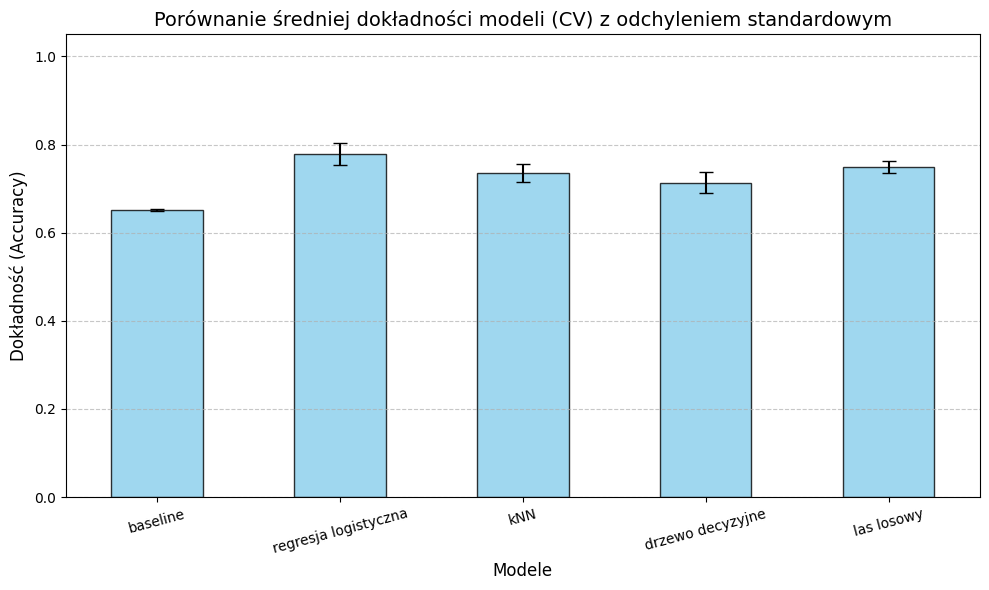

In [9]:
# Twoje rozwiązanie
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# 1. Definicja słownika z modelami i ich nazwami (używamy funkcji model_z z poprzedniego kroku)
modele = {
    "baseline": DummyClassifier(strategy="most_frequent"),
    "regresja logistyczna": LogisticRegression(),
    "kNN": KNeighborsClassifier(),
    "drzewo decyzyjne": DecisionTreeClassifier(random_state=42),
    "las losowy": RandomForestClassifier(random_state=42),
}

# Przygotowanie list na wyniki
wyniki_cv_mean = []
wyniki_cv_std = []
wyniki_train = []

# 2. Pętla licząca cross_val_score oraz accuracy na pełnym zbiorze treningowym
for nazwa, classifier in modele.items():
    # Tworzymy pełny pipeline za pomocą zdefiniowanej wcześniej funkcji model_z
    pipeline = model_z(classifier)

    # Obliczamy CV score przy użyciu zdefiniowanego wcześniej obiektu cv (StratifiedKFold)
    scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring="accuracy")
    wyniki_cv_mean.append(scores.mean())
    wyniki_cv_std.append(scores.std())

    # Trenujemy na całym zbiorze treningowym i liczymy accuracy
    pipeline.fit(X_train, y_train)
    y_pred_train = pipeline.predict(X_train)
    wyniki_train.append(accuracy_score(y_train, y_pred_train))

# 3. Zebranie wyników w DataFrame
porownanie = pd.DataFrame(
    {
        "CV średnia": wyniki_cv_mean,
        "CV odch.": wyniki_cv_std,
        "train": wyniki_train,
    },
    index=modele.keys(),
)

# Wyświetlenie tabeli
print(porownanie)

# 4. Wykres słupkowy średnich z odchyleniami (yerr)
fig, ax = plt.subplots(figsize=(10, 6))
porownanie["CV średnia"].plot(
    kind="bar",
    yerr=porownanie["CV odch."],
    ax=ax,
    color="skyblue",
    edgecolor="black",
    capsize=5,
    alpha=0.8,
)

ax.set_title("Porównanie średniej dokładności modeli (CV) z odchyleniem standardowym", fontsize=14)
ax.set_ylabel("Dokładność (Accuracy)", fontsize=12)
ax.set_xlabel("Modele", fontsize=12)
ax.set_ylim(0, 1.05)
plt.xticks(rotation=15)
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

In [10]:
# TEST
assert list(porownanie.index) == ["baseline", "regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"]
assert abs(porownanie.loc["baseline", "CV średnia"] - 0.651) < 1e-2
assert abs(porownanie.loc["regresja logistyczna", "CV średnia"] - 0.778) < 1e-2
assert porownanie.loc["drzewo decyzyjne", "train"] > 0.99
print("5 OK")

5 OK


---
## 6. Krzywa walidacji dla kNN
Policz `validation_curve` dla `kneighborsclassifier__n_neighbors` w `ks = [1, 3, 5, 7, 11, 15, 21, 31, 51]`. Wyniki zapisz w `tren`, `walid`; narysuj średnie (trening i walidacja) w funkcji k.

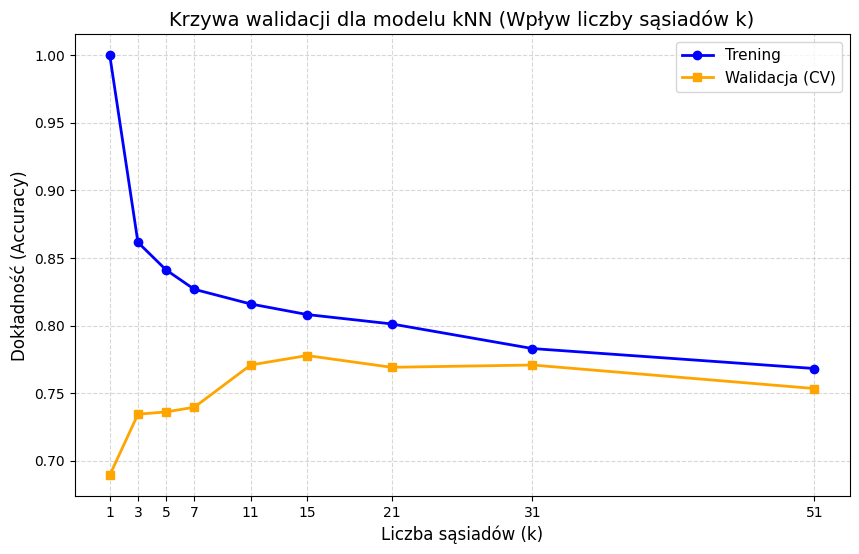

In [11]:
# Twoje rozwiązanie
from sklearn.model_selection import validation_curve

# 1. Definicja badanych wartości parametru k
ks = [1, 3, 5, 7, 11, 15, 21, 31, 51]

# 2. Tworzenie bazowego pipeline dla kNN
pipeline_knn = model_z(KNeighborsClassifier())

# 3. Obliczenie krzywej walidacji
tren, walid = validation_curve(
    estimator=pipeline_knn,
    X=X_train,
    y=y_train,
    param_name="classifier__n_neighbors", # W pipeline nazwa parametru to: nazwa_kroku__nazwa_parametru
    param_range=ks,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

# 4. Obliczenie średnich wyników dla zbioru treningowego i walidacyjnego
tren_mean = tren.mean(axis=1)
walid_mean = walid.mean(axis=1)

# 5. Rysowanie wykresu krzywej walidacji
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(ks, tren_mean, marker="o", label="Trening", color="blue", linewidth=2)
ax.plot(ks, walid_mean, marker="s", label="Walidacja (CV)", color="orange", linewidth=2)

ax.set_title("Krzywa walidacji dla modelu kNN (Wpływ liczby sąsiadów k)", fontsize=14)
ax.set_xlabel("Liczba sąsiadów (k)", fontsize=12)
ax.set_ylabel("Dokładność (Accuracy)", fontsize=12)
ax.set_xticks(ks)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(fontsize=11)

plt.show()

In [12]:
# TEST
assert tren.shape == (9, 5) and walid.shape == (9, 5)
assert tren.mean(axis=1)[0] == 1.0, "Dla k=1 wynik treningowy powinien wynosić 1.0"
print("6 OK")

6 OK


*Twoja odpowiedź:* dlaczego dla k = 1 wynik treningowy wynosi dokładnie 1.0? Gdzie jest przeuczenie, a gdzie niedouczenie?

Wynik treningowy wynosi dokładnie 1.0, ponieważ wynika to ze specyfiki algorytmu kNN - przy szukaniu jednego $(k=1)$ najbliższego sąsiada dla punktu ze zbioru treningowego, model znajduje ten sam punkt. Kopiuje więc jego własną, poprawną etykietę, co daje 100% dokładności.

Przeuczenie (overfitting) występuje dla bardzo małych wartości $k$ $(k=1, 3)$. Model jest zbyt skomplikowany, idealnie dopasowuje się do danych treningowych (szumu i anomalii), co skutkuje wysokim accuracy na treningu i wyraźnie gorszym na walidacji.

Niedouczenie (underfitting) występuje dla bardzo dużych wartości $k$ $(k \ge 31)$. Model staje się zbyt prosty, ignoruje lokalne wzorce i podejmuje decyzje na podstawie globalnej większości klasowej. Dokładność na zbiorze treningowym i walidacyjnym drastycznie spada, zbliżając się do poziomu baseline $(≈ 65)$.

---
## 7. Strojenie: `GridSearchCV`
Dla każdego z czterech klasyfikatorów uruchom `GridSearchCV(model_z(...), siatka, cv=cv)` na zbiorze treningowym. Siatki:
- regresja logistyczna: `C` ∈ {0.01, 0.1, 1, 10, 100},
- kNN: `n_neighbors` ∈ {1, 3, 5, 7, 11, 15, 21, 31},
- drzewo: `max_depth` ∈ {2, 3, 4, 5, 6, 8, None},
- las losowy: `max_depth` ∈ {3, 5, 8, None}, `n_estimators` ∈ {100, 300}.

Nauczone obiekty zapisz w słowniku `wyniki_gs` (klucze jak w punkcie 5, bez baseline'u) i wypisz najlepsze parametry oraz `best_score_` każdego modelu.

In [13]:
# Twoje rozwiązanie
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# 1. Definicja modeli bazowych
modele_gs = {
    "regresja logistyczna": LogisticRegression(),
    "kNN": KNeighborsClassifier(),
    "drzewo decyzyjne": DecisionTreeClassifier(random_state=42),
    "las losowy": RandomForestClassifier(random_state=42),
}

# 2. Definicja siatek parametrów
siatki = {
    "regresja logistyczna": {"classifier__C": [0.01, 0.1, 1, 10, 100]},
    "kNN": {"classifier__n_neighbors": [1, 3, 5, 7, 11, 15, 21, 31]},
    "drzewo decyzyjne": {
        "classifier__max_depth": [2, 3, 4, 5, 6, 8, None]
    },
    "las losowy": {
        "classifier__max_depth": [3, 5, 8, None],
        "classifier__n_estimators": [100, 300],
    },
}

# Słownik na nauczone obiekty GridSearchCV
wyniki_gs = {}

# 3. Pętla uruchamiająca przeszukiwanie siatki dla każdego modelu
for nazwa, classifier in modele_gs.items():
    # Tworzymy bazowy pipeline
    pipeline = model_z(classifier)

    # Inicjalizacja GridSearchCV
    gs = GridSearchCV(
        estimator=pipeline,
        param_grid=siatki[nazwa],
        cv=cv,
        scoring="accuracy",
        n_jobs=-1,
    )

    # Trenowanie na zbiorze treningowym
    gs.fit(X_train, y_train)

    # Zapisanie nauczonego obiektu do słownika
    wyniki_gs[nazwa] = gs

    # Wypisanie wyników
    print(f"--- {nazwa.upper()} ---")
    print(f"Najlepsze parametry: {gs.best_params_}")
    print(f"Najlepszy wynik (CV Accuracy): {gs.best_score_:.4f}\n")

--- REGRESJA LOGISTYCZNA ---
Najlepsze parametry: {'classifier__C': 1}
Najlepszy wynik (CV Accuracy): 0.7779

--- KNN ---
Najlepsze parametry: {'classifier__n_neighbors': 15}
Najlepszy wynik (CV Accuracy): 0.7778

--- DRZEWO DECYZYJNE ---
Najlepsze parametry: {'classifier__max_depth': 5}
Najlepszy wynik (CV Accuracy): 0.7500

--- LAS LOSOWY ---
Najlepsze parametry: {'classifier__max_depth': 3, 'classifier__n_estimators': 300}
Najlepszy wynik (CV Accuracy): 0.7622



In [14]:
# TEST
assert set(wyniki_gs) == {"regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"}
assert all(hasattr(gs, "best_estimator_") for gs in wyniki_gs.values())
assert all(gs.best_score_ > 0.7 for gs in wyniki_gs.values())
print("7 OK")

7 OK


---
## 8. Wybór modelu i ocena końcowa
1. `najlepszy` – nazwa modelu z najwyższym `best_score_`; `model_koncowy` – jego `best_estimator_`.
2. `acc_test` – accuracy `model_koncowy` na zbiorze testowym (**jedyny raz, kiedy używasz `X_test`**).
3. Macierz pomyłek (`ConfusionMatrixDisplay`) i `classification_report`.

Najlepszy model na podstawie CV: REGRESJA LOGISTYCZNA
Najlepszy wynik walidacji krzyżowej (CV score): 0.7779
Dokładność na zbiorze testowym (acc_test): 0.7240

--- RAPORT KLASYFIKACJI ---
              precision    recall  f1-score   support

  Zdrowa (0)       0.76      0.84      0.80       125
   Chora (1)       0.63      0.51      0.56        67

    accuracy                           0.72       192
   macro avg       0.70      0.67      0.68       192
weighted avg       0.72      0.72      0.72       192

--- MACIERZ POMYŁEK ---


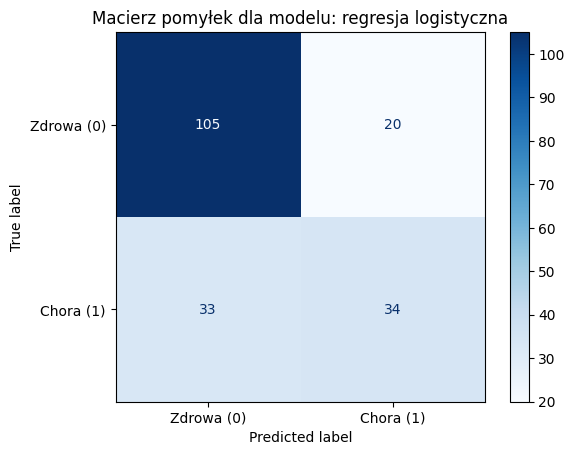

In [15]:
# Twoje rozwiązanie
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# 1. Automatyczny wybór najlepszego modelu z wynikami GridSearchCV
najlepszy = max(wyniki_gs, key=lambda k: wyniki_gs[k].best_score_)
model_koncowy = wyniki_gs[najlepszy].best_estimator_ # Szukamy klucza w słowniku wyniki_gs, który ma najwyższy best_score_

# 2. Ewaluacja na zbiorze testowym (pierwszy i jedyny raz!)
acc_test = model_koncowy.score(X_test, y_test)

# Wypisanie podsumowania wyboru
print(f"Najlepszy model na podstawie CV: {najlepszy.upper()}")
print(f"Najlepszy wynik walidacji krzyżowej (CV score): {wyniki_gs[najlepszy].best_score_:.4f}")
print(f"Dokładność na zbiorze testowym (acc_test): {acc_test:.4f}\n")

# 3. Generowanie prognoz do raportów
y_pred = model_koncowy.predict(X_test)

# 4. Wyświetlenie raportu klasyfikacji (classification_report)
print("--- RAPORT KLASYFIKACJI ---")
print(classification_report(y_test, y_pred, target_names=["Zdrowa (0)", "Chora (1)"]))

# 5. Wyświetlenie macierzy pomyłek (ConfusionMatrixDisplay)
print("--- MACIERZ POMYŁEK ---")
disp = ConfusionMatrixDisplay.from_estimator(
    model_koncowy,
    X_test,
    y_test,
    display_labels=["Zdrowa (0)", "Chora (1)"],
    cmap="Blues"
)
plt.title(f"Macierz pomyłek dla modelu: {najlepszy}")
plt.show()

In [16]:
# TEST
assert najlepszy == max(wyniki_gs, key=lambda n: wyniki_gs[n].best_score_)
assert 0.65 < acc_test < 0.9
print("8 OK")

8 OK


*Twoja odpowiedź:*
1. Jak wynik testowy ma się do szacunku z walidacji krzyżowej? Czy różnica cię niepokoi? (Zbiór testowy ma 192 pacjentki – ile p.p. to jedna osoba?)
2. Jaki jest recall dla klasy „cukrzyca”? Co oznacza on dla pacjentek? Czy accuracy to dobra metryka do wyboru modelu w tym zastosowaniu?
3. Modele w czołówce różnią się w CV o 1–2 p.p., a odchylenia wynoszą ok. 2–3 p.p. Czy można jednoznacznie wskazać „najlepszy” algorytm?

---

1.
- Jedna osoba w zbiorze testowym (1 z 192 pacjentek) to dokładnie około 0,52 punktu procentowego (p.p.)

- Różnica między CV score (77,79%) a testowym accuracy (72,40%) wynosi 5,39 p.p., co oznacza, że na zbiorze testowym model błędnie sklasyfikował o około 10 pacjentek więcej niż wynosiła średnia z walidacji

- Taka rozbieżność jest zauważalna, ale nie jest wysoce niepokojąca - mieści się w granicach błędu standardowego małej próby testowej oraz naturalnego szumu statystycznego, wskazując jedynie na lekki optymizm estymacji CV

2.
- Recall dla klasy chorych wynosi dokładnie 51% (0.51), co oznacza, że model pomija i nie wykrywa aż 49% chorych pacjentek (w zbiorze testowym przeoczył 33 z 67 chorych kobiet)

- Dla pacjentek oznacza to wysokie ryzyko nieotrzymania pomocy medycznej na czas pomimo rozwoju choroby

- Accuracy to zła metryka w tym zastosowaniu. Ogólny wynik testu na poziomie 72% maskuje tragiczny stan diagnostyki osób chorych, ponieważ model "wybija się" na poprawnej klasyfikacji osób zdrowych (recall 84%). Z perspektywy medycznej priorytetem jest wysoki Recall lub zbalansowana metryka F1-score / AUC-ROC

3.
- Nie można jednoznacznie wskazać jednego najlepszego algorytmu, mimo że uzyskała najwyższy best_score_ (77,79%).

- Różnica w wynikach modeli (1-2 p.p.) jest mniejsza niż błąd pomiaru i odchylenie standardowe walidacji krzyżowej (2-3 p.p.)

- Wyniki najlepszych algorytmów (np. regresji logistycznej i lasu losowego) nakładają się na siebie, przez co różnice między nimi są statystycznie nieistotne. Ostateczna kolejność na podium zależy od losowego podziału danych

---
## 9. Dla chętnych
1. Powtórz punkty 7–8 z `scoring="recall"` w `GridSearchCV`. Czy zmienił się wybrany model? Co stało się z precision?
2. Dodaj do imputera `add_indicator=True` (flagi braków). Czy sam fakt braku pomiaru insuliny niesie informację?
3. Sprawdź, jak wyglądałyby wyniki, gdyby zostawić zera zamiast `NaN` (punkt 3 pominięty). Czy różnica jest duża? Dlaczego może być mała?

In [17]:
# 9.1
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV

# Słowniki na nowe wyniki optymalizacji pod kątem RECALL
wyniki_gs_recall = {}

# 1. Pętla GridSearchCV ze zmianą metryki na scoring="recall"
for nazwa, classifier in modele_gs.items():
    pipeline = model_z(classifier)

    gs = GridSearchCV(
        estimator=pipeline,
        param_grid=siatki[nazwa],
        cv=cv,
        scoring="recall",  # Zmiana kryterium optymalizacji!
        n_jobs=-1,
    )

    gs.fit(X_train, y_train)
    wyniki_gs_recall[nazwa] = gs

# 2. Wybór najlepszego estymatora według nowej metryki
najlepszy_recall = max(
    wyniki_gs_recall, key=lambda k: wyniki_gs_recall[k].best_score_
)
model_koncowy_recall = wyniki_gs_recall[najlepszy_recall].best_estimator_

# 3. Ewaluacja na zbiorze testowym
y_pred_recall = model_koncowy_recall.predict(X_test)

print(f"Najlepszy model (Recall CV): {najlepszy_recall.upper()}")
print(f"Najlepszy średni Recall w CV: {wyniki_gs_recall[najlepszy_recall].best_score_:.4f}\n")
print("--- RAPORT KLASYFIKACJI (ZOPTALIMALIZOWANY POD RECALL) ---")
print(
    classification_report(
        y_test, y_pred_recall, target_names=["Zdrowa (0)", "Chora (1)"]
    )
)

Najlepszy model (Recall CV): DRZEWO DECYZYJNE
Najlepszy średni Recall w CV: 0.6517

--- RAPORT KLASYFIKACJI (ZOPTALIMALIZOWANY POD RECALL) ---
              precision    recall  f1-score   support

  Zdrowa (0)       0.80      0.82      0.81       125
   Chora (1)       0.65      0.61      0.63        67

    accuracy                           0.75       192
   macro avg       0.72      0.72      0.72       192
weighted avg       0.75      0.75      0.75       192



- Czy zmienił się wybrany model?
Tak, model końcowy uległ zmianie - Regresję Logistyczną zastąpiło Drzewo Decyzyjne. Przy kryterium scoring="recall" algorytm zmienił swoje hiperparametry (np. zmniejszył głębokość drzewa max_depth), aby agresywniej szukać sygnałów choroby, co pozwoliło mu osiągnąć najwyższy średni Recall w CV (65,17%)


- Co stało się z precision i recall na zbiorze testowym?
Nastąpił wyraźny wzrost czułości (Recall) kosztem stabilizacji precyzji.
  - Recall dla klasy "Chora" wzrósł z 51% do 61% (model poprawnie wykrył o 7 chorych pacjentek więcej; 41 zamiast 34)

  - Precision utrzymało się na niemal identycznym poziomie (wzrost z 63% do 65%), co w połączeniu z wyższym recall podniosło także ogólne accuracy testowe do 75%. Zmiana kryterium optymalizacji pozwoliła drzewu decyzyjnemu znaleźć znacznie lepszą, bezpieczniejszą medycznie granicę decyzyjną

In [18]:
# 9.2
# Nadpisujemy funkcję, aby każdy nowy pipeline automatycznie tworzył flagi braków danych.
def model_z(klasyfikator):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)), # Flagi włączone!
        ("scaler", StandardScaler()),
        ("classifier", klasyfikator)
    ])

# Słowniki na nowe wyniki optymalizacji pod kątem RECALL
wyniki_gs_recall = {}

# 1. Pętla GridSearchCV ze zmianą metryki na scoring="recall"
for nazwa, classifier in modele_gs.items():
    pipeline = model_z(classifier) # Pobiera zaktualizowany pipeline z add_indicator=True

    gs = GridSearchCV(
        estimator=pipeline,
        param_grid=siatki[nazwa],
        cv=cv,
        scoring="recall",  # Zmiana kryterium optymalizacji!
        n_jobs=-1,
    )
    gs.fit(X_train, y_train)
    wyniki_gs_recall[nazwa] = gs

# 2. Wybór najlepszego estymatora według nowej metryki
najlepszy_recall = max(wyniki_gs_recall, key=lambda k: wyniki_gs_recall[k].best_score_)
model_koncowy_recall = wyniki_gs_recall[najlepszy_recall].best_estimator_

# 3. Ewaluacja na zbiorze testowym
y_pred_recall = model_koncowy_recall.predict(X_test)

print(f"Najlepszy model (Recall CV): {najlepszy_recall.upper()}")
print(f"Najlepszy średni Recall w CV: {wyniki_gs_recall[najlepszy_recall].best_score_:.4f}\n")

print("--- RAPORT KLASYFIKACJI (ZOPTALIMALIZOWANY POD RECALL) ---")
print(classification_report(y_test, y_pred_recall, target_names=["Zdrowa (0)", "Chora (1)"]))

Najlepszy model (Recall CV): DRZEWO DECYZYJNE
Najlepszy średni Recall w CV: 0.6467

--- RAPORT KLASYFIKACJI (ZOPTALIMALIZOWANY POD RECALL) ---
              precision    recall  f1-score   support

  Zdrowa (0)       0.80      0.82      0.81       125
   Chora (1)       0.65      0.61      0.63        67

    accuracy                           0.75       192
   macro avg       0.72      0.72      0.72       192
weighted avg       0.75      0.75      0.75       192



- Czy sam fakt braku pomiaru insuliny niesie informację?

Tak, wynik wyraźnie potwierdza, że sam fakt braku pomiaru insuliny niesie istotną informację.

Wprowadzenie parametru `add_indicator=True` do imputera pozwoliło na jawne zakodowanie informacji o braku pomiarów jako dodatkowych cech binarIndependent. Przeprowadzona optymalizacja pod kątem czułości (`scoring="recall"`) wskazała **drzewo decyzyjne** jako najlepszy model (średni Recall CV = **0.6467**, Recall na zbiorze testowym dla klasy chorób = **0.61**)


In [19]:
# 9.3
# 1. Pipeline bez imputera (skoro nie ma NaN, SimpleImputer nic nie zrobi)
pipeline_zera = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", DecisionTreeClassifier(max_depth=5, random_state=42)) # Parametry wybranego drzewa
])

# 2. Dopasowanie modelu do oryginalnych danych z zerami
pipeline_zera.fit(X_train, y_train)
y_pred_zera = pipeline_zera.predict(X_test)

print("--- RAPORT DLA DANYCH Z ZERAMI (BEZ IMPUTACJI) ---")
print(classification_report(y_test, y_pred_zera, target_names=["Zdrowa (0)", "Chora (1)"]))

--- RAPORT DLA DANYCH Z ZERAMI (BEZ IMPUTACJI) ---
              precision    recall  f1-score   support

  Zdrowa (0)       0.81      0.84      0.82       125
   Chora (1)       0.68      0.63      0.65        67

    accuracy                           0.77       192
   macro avg       0.74      0.73      0.74       192
weighted avg       0.76      0.77      0.76       192



- Czy różnica w wynikach jest duża?

Nie, różnica jest **bardzo mała**, a model działający na surowych zerach osiągnął nawet minimalnie lepsze wyniki. Czułość (Recall) dla klasy osób chorych wzrosła z **0.61** (wariant z `add_indicator=True` i imputacją) do **0.63** (wariant z surowymi zerami), a ogólna dokładność (Accuracy) podniosła się z **0.75** do **0.77**

- Dlaczego może być mała?
1. **Zera jako naturalna flaga braku dla drzewa:** Drzewo decyzyjne jest algorytmem nieliniowym, który dzieli dane za pomocą progów (reguł IF-THEN). Ponieważ fizjologicznie poziomy insuliny czy glukozy nigdy nie wynoszą dokładnie `0`, wartość ta znajduje się na samym brzegu rozkładu. Drzewo mogło dokonać idealnego cięcia (np. `insulina <= 0`), traktując zero dokładnie tak samo jak jawną flagę braku

2. **Brak zaburzeń w strukturze danych przez imputację:** Wprowadzenie `SimpleImputer(strategy="median")` zastępuje wartości zerowe sztuczną medianą wyliczoną z rozkładu. Choć dodanie `add_indicator=True` chroni informację o braku, to sztuczne przesunięcie brakujących wartości do środka rozkładu mogło nieznacznie utrudnić drzewu separację pacjentów. Pozostawienie zer pozwoliło modelowi na czystszy podział binarny na skraju cechy, co przełożyło się na drobny wzrost precyzji i czułości